# k-means clustering

Companion notebook for the *k-means clustering* slides. Each idea is written first by hand
with NumPy and then with the scikit-learn class that does the same job.

**Data:** 300 synthetic points in 2-D from `make_blobs`, generated around 4 centers. The labels are thrown away.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.pairwise import euclidean_distances

RANDOM_STATE = 42
K = 4
K_CHOICES = range(1, 11)
MAX_STEPS = 100

X, _ = make_blobs(n_samples=300, centers=K, cluster_std=2.0, random_state=RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)
start = X[rng.choice(len(X), size=K, replace=False)]

## 1. Distance to a centroid

$\lVert \mathbf{x}_i - \boldsymbol{\mu}_k \rVert^2 = \sum_j (x_{ij} - \mu_{kj})^2$, for every example against every starting centroid.

In [2]:
sq_distances_by_hand = ((X[:, None, :] - start[None, :, :]) ** 2).sum(axis=2)
print("distance table:", sq_distances_by_hand.shape)
print("same result:", np.allclose(sq_distances_by_hand, euclidean_distances(X, start, squared=True)))

distance table: (300, 4)
same result: True


## 2. Assign, update, repeat

Assign: $c_i = \arg\min_k \lVert \mathbf{x}_i - \boldsymbol{\mu}_k \rVert^2$. Update: $\boldsymbol{\mu}_k = \frac{1}{|C_k|}\sum_{i \in C_k} \mathbf{x}_i$.
Stop when no example changes cluster.

stopped after 4 rounds


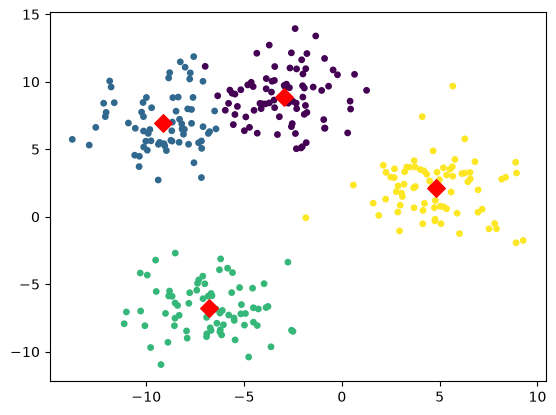

In [3]:
centroids = start.copy()
labels = np.full(len(X), -1)
for step in range(MAX_STEPS):
    new_labels = euclidean_distances(X, centroids, squared=True).argmin(axis=1)
    if np.array_equal(new_labels, labels):
        break
    labels = new_labels
    centroids = np.array([X[labels == k].mean(axis=0) for k in range(K)])
print("stopped after", step, "rounds")

plt.scatter(X[:, 0], X[:, 1], c=labels, s=15)
plt.scatter(centroids[:, 0], centroids[:, 1], c="red", marker="D", s=80)
plt.show()

scikit-learn started from the same centroids, with a single run, follows the same steps.
Cluster numbers are arbitrary, so the labels are compared with the adjusted Rand index (1 means the same grouping).

In [4]:
kmeans = KMeans(n_clusters=K, init=start, n_init=1, algorithm="lloyd").fit(X)
print("same grouping:", adjusted_rand_score(labels, kmeans.labels_) == 1.0)
print("same centroid for every example:", np.allclose(centroids[labels], kmeans.cluster_centers_[kmeans.labels_]))

same grouping: True
same centroid for every example: True


## 3. Inertia

k-means makes the within-cluster sum of squares small: $J = \sum_{k=1}^{K}\sum_{i \in C_k} \lVert \mathbf{x}_i - \boldsymbol{\mu}_k \rVert^2$.

In [5]:
inertia_by_hand = ((X - centroids[labels]) ** 2).sum()
print(f"J = {inertia_by_hand:.1f} | same result:", np.isclose(inertia_by_hand, kmeans.inertia_))

J = 2185.0 | same result: True


## 4. Choosing K: the elbow

More clusters always lower $J$. Look for the $K$ after which the curve flattens.
Each $K$ keeps the best of 10 runs with k-means++ starts.

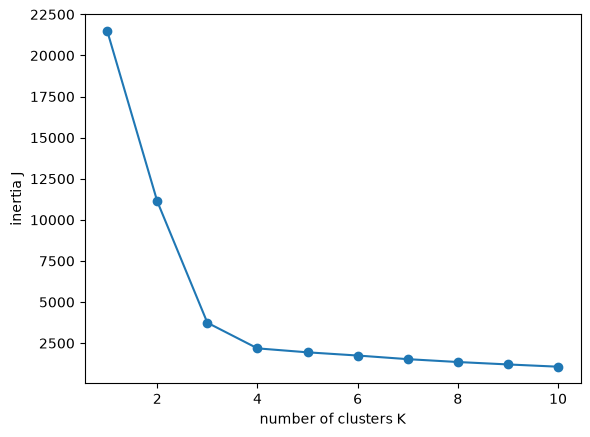

In [6]:
inertias = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X).inertia_ for k in K_CHOICES]

plt.plot(K_CHOICES, inertias, marker="o")
plt.xlabel("number of clusters K")
plt.ylabel("inertia J")
plt.show()

## Exercises

1. Pick other random starting centroids in the constants cell. Does the final $J$ change? Why?
2. Multiply the first feature of `X` by 100 and run section 2 again. What happens to the clusters?
3. Check that the update step never increases $J$: print the inertia after every assign and every update.